#### Undersampling with RandomUnderSampler
With RandomUnderSampler, no need to process the dataset into all numeric format (categories etc.).

In [8]:
# pip install imblearn
import pandas as pd
import numpy as np
import seaborn as sns
from imblearn.under_sampling import RandomUnderSampler

# load the data
df = pd.read_csv("../../HeartDisease_cleaned.csv")
df.head(3)

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST
0,40,1,140,289,0,172,0,0.0,3,0,0,1,0,0,0,1,0
1,49,0,160,180,0,156,0,1.0,2,1,0,0,1,0,0,1,0
2,37,1,130,283,0,98,0,0.0,3,0,0,1,0,0,0,0,1


In [9]:
# We're not allowed to have NaN values in the dataset once we use undersampling here.
df = df.dropna()

<Axes: xlabel='HeartDisease', ylabel='Count'>

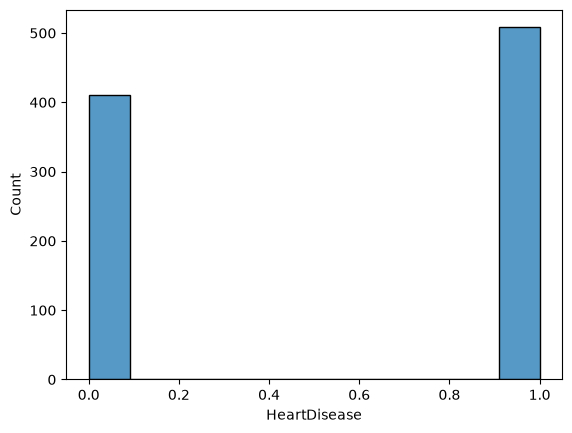

In [10]:
# let's see our current target distribution
# df["Rating"].value_counts()

sns.histplot(df, x="HeartDisease")

#### Perform RandomUnderSampling

In [11]:
from imblearn.under_sampling import RandomUnderSampler

# Split the dataset. If we don't do this, we WILL have a data leakage when training
# the model.
X = df.drop(columns="HeartDisease", axis=1)
y = df["HeartDisease"]

# We set a stable seed for the sampler.
sampler = RandomUnderSampler(random_state=321)

# We use the sampler, and output two variables (X, y respectively).
X_resampled, y_resampled = sampler.fit_resample(X, y)

# Let's make an independent dataframe to be safe.
df_resampled = X_resampled.copy()

# And let's add the `Pop` column back into it.
df_resampled["HeartDisease"] = y_resampled

<Axes: xlabel='HeartDisease', ylabel='Count'>

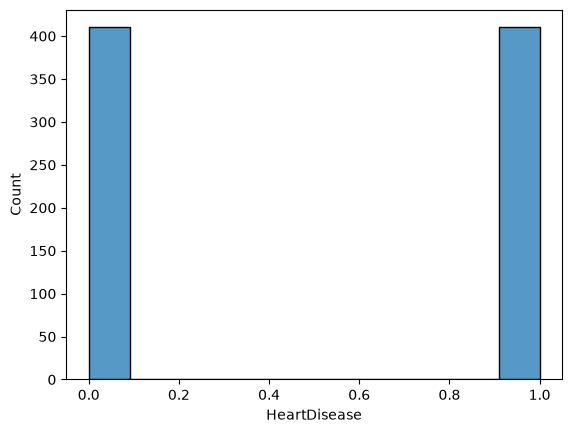

In [12]:
# we now have approximately 100 rows of data (80% lost)
sns.histplot(df_resampled, x="HeartDisease")

In [13]:

df_resampled

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,HeartDisease
0,40,1,140,289,0,172,0,0.0,3,0,1,0,0,0,1,0,0
2,37,1,130,283,0,98,0,0.0,3,0,1,0,0,0,0,1,0
4,54,1,150,195,0,122,0,0.0,3,0,0,1,0,0,1,0,0
5,39,1,120,339,0,170,0,0.0,3,0,0,1,0,0,1,0,0
6,45,0,130,237,0,170,0,0.0,3,0,1,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
466,55,1,120,0,0,125,1,2.5,2,0,0,1,0,0,0,1,1
804,70,1,160,269,0,112,1,2.9,2,0,0,1,0,0,1,0,1
131,46,1,110,202,0,150,1,0.0,2,1,0,0,0,0,1,0,1
888,52,1,128,204,1,156,1,1.0,2,1,0,0,0,0,1,0,1


#### Let's compare the statistics before and after
First, basic statistics with describe()!

In [14]:
df.describe()

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,0.789760,132.396514,198.799564,0.233115,136.809368,0.404139,0.887364,2.361656,0.553377,0.540305,0.188453,0.221133,0.050109,0.204793,0.601307,0.193900
std,9.432617,0.407701,18.514154,109.384145,0.423046,25.460334,0.490992,1.066570,0.607056,0.497414,0.498645,0.391287,0.415236,0.218289,0.403770,0.489896,0.395567
min,28.000000,0.000000,0.000000,0.000000,0.000000,60.000000,0.000000,-2.600000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.000000,1.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,54.000000,1.000000,130.000000,223.000000,0.000000,138.000000,0.000000,0.600000,2.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
75%,60.000000,1.000000,140.000000,267.000000,0.000000,156.000000,1.000000,1.500000,3.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,77.000000,1.000000,200.000000,603.000000,1.000000,202.000000,1.000000,6.200000,3.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [15]:
df_resampled.describe()

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,HeartDisease
count,820.000000,820.000000,820.000000,820.000000,820.000000,820.000000,820.000000,820.000000,820.000000,820.000000,820.000000,820.000000,820.000000,820.000000,820.000000,820.000000,820.000000
mean,53.296341,0.776829,132.340244,201.081707,0.213415,138.045122,0.379268,0.852195,2.401220,0.513415,0.203659,0.229268,0.053659,0.208537,0.601220,0.190244,0.500000
std,9.635163,0.416626,18.682034,105.348329,0.409968,25.312053,0.485501,1.053181,0.610249,0.500125,0.402964,0.420619,0.225480,0.406510,0.489946,0.392733,0.500305
min,28.000000,0.000000,0.000000,0.000000,0.000000,63.000000,0.000000,-2.600000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,46.000000,1.000000,120.000000,177.000000,0.000000,120.000000,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,54.000000,1.000000,130.000000,223.000000,0.000000,140.000000,0.000000,0.500000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.500000
75%,60.000000,1.000000,140.000000,266.000000,0.000000,157.000000,1.000000,1.500000,3.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000
max,77.000000,1.000000,200.000000,564.000000,1.000000,202.000000,1.000000,6.200000,3.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [16]:
# switching to decimal notation for the variance checks
pd.set_option('display.float_format', lambda x: "%.2f" % x)

In [17]:
df.var(numeric_only=True)

Age                    88.97
Sex                     0.17
RestingBP             342.77
Cholesterol         11964.89
FastingBS               0.18
MaxHR                 648.23
ExerciseAngina          0.24
Oldpeak                 1.14
ST_Slope                0.37
HeartDisease            0.25
ChestPainType_ASY       0.25
ChestPainType_ATA       0.15
ChestPainType_NAP       0.17
ChestPainType_TA        0.05
RestingECG_LVH          0.16
RestingECG_Normal       0.24
RestingECG_ST           0.16
dtype: float64

In [18]:
df_resampled.var(numeric_only=True)

Age                    92.84
Sex                     0.17
RestingBP             349.02
Cholesterol         11098.27
FastingBS               0.17
MaxHR                 640.70
ExerciseAngina          0.24
Oldpeak                 1.11
ST_Slope                0.37
ChestPainType_ASY       0.25
ChestPainType_ATA       0.16
ChestPainType_NAP       0.18
ChestPainType_TA        0.05
RestingECG_LVH          0.17
RestingECG_Normal       0.24
RestingECG_ST           0.15
HeartDisease            0.25
dtype: float64